In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
sns.set_palette("Set2")
print("Libraries imported successfully")

Libraries imported successfully!


In [6]:

df = pd.read_excel("WA_Fn-UseC_-Telco-Customer-Churn.xlsx")

print("Dataset Shape (Rows, Columns):", df.shape)
print("\n--- First 5 Records ---")
display(df.head())

print("\n--- Column Info & Data Types ---")
print(df.info())

print("\n--- Summary Statistics (Numerical) ---")
display(df.describe())

Dataset Shape (Rows, Columns): (7043, 21)

--- First 5 Records ---


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



--- Column Info & Data Types ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  Paperles

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [7]:
if 'customerID' in df.columns:
    df.drop(columns=['customerID'], inplace=True)

df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

print("Missing values in TotalCharges:", df['TotalCharges'].isnull().sum())
df['TotalCharges'].fillna(0, inplace=True)

print("Duplicate rows count:", df.duplicated().sum())
df.drop_duplicates(inplace=True)

redundant_cols = ['MultipleLines', 'OnlineSecurity', 'OnlineBackup',
                  'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies']
for col in redundant_cols:
    df[col] = df[col].replace({'No internet service': 'No', 'No phone service': 'No'})

print("\nCleaned Data Summary:")
print(df.info())

Missing values in TotalCharges: 11
Duplicate rows count: 22


/tmp/ipykernel_651/537969293.py:7: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['TotalCharges'].fillna(0, inplace=True)



Cleaned Data Summary:
<class 'pandas.core.frame.DataFrame'>
Index: 7021 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7021 non-null   object 
 1   SeniorCitizen     7021 non-null   int64  
 2   Partner           7021 non-null   object 
 3   Dependents        7021 non-null   object 
 4   tenure            7021 non-null   int64  
 5   PhoneService      7021 non-null   object 
 6   MultipleLines     7021 non-null   object 
 7   InternetService   7021 non-null   object 
 8   OnlineSecurity    7021 non-null   object 
 9   OnlineBackup      7021 non-null   object 
 10  DeviceProtection  7021 non-null   object 
 11  TechSupport       7021 non-null   object 
 12  StreamingTV       7021 non-null   object 
 13  StreamingMovies   7021 non-null   object 
 14  Contract          7021 non-null   object 
 15  PaperlessBilling  7021 non-null   object 
 16  PaymentMethod     7021 n

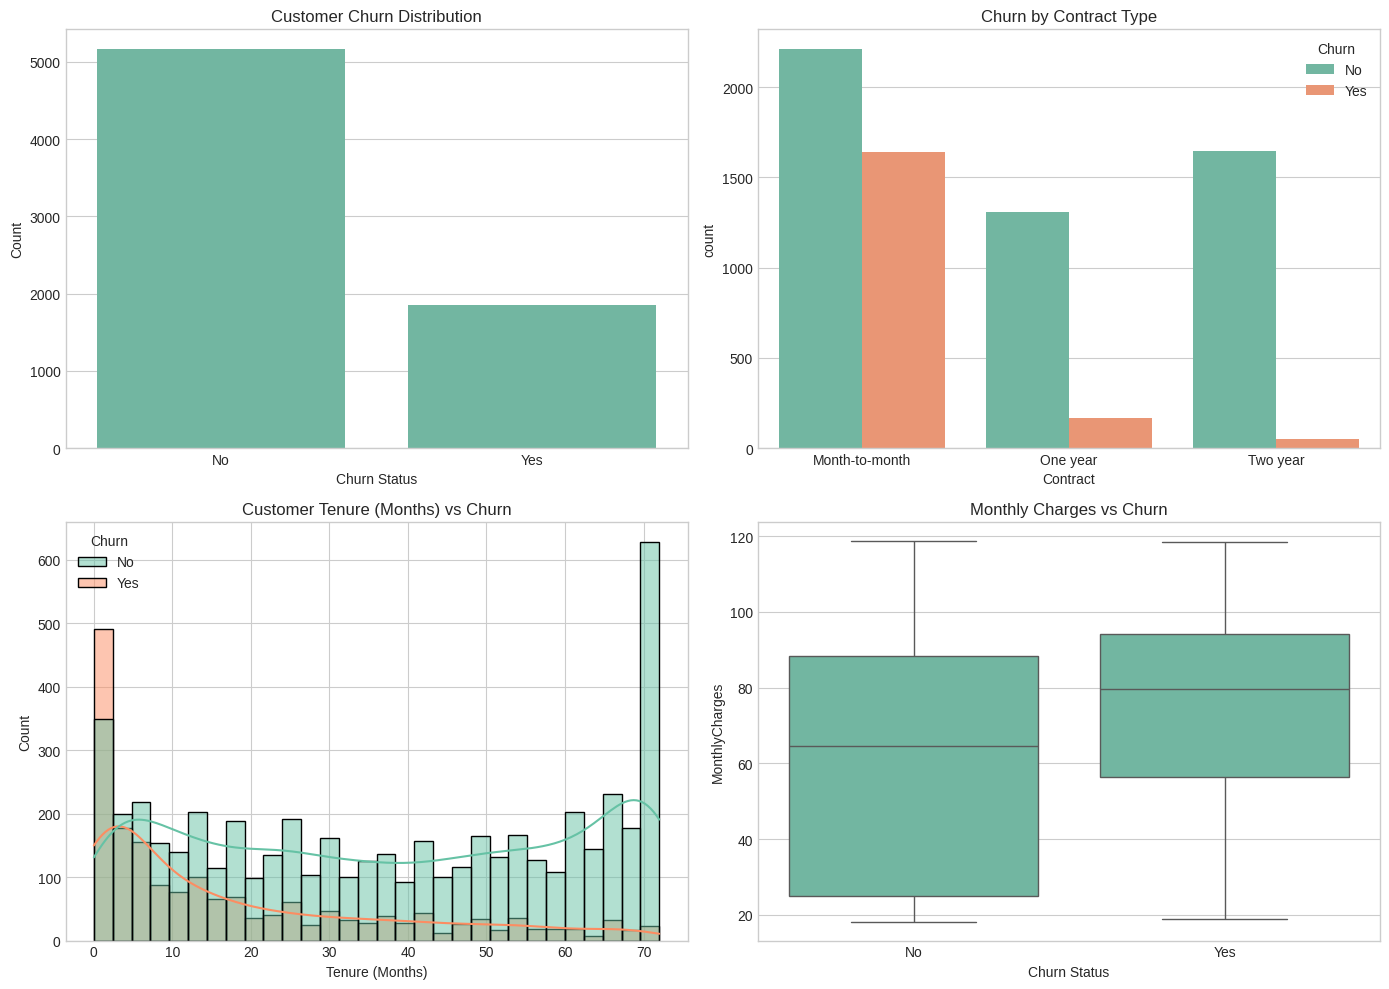

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.countplot(data=df, x='Churn', ax=axes[0, 0])
axes[0, 0].set_title("Customer Churn Distribution")
axes[0, 0].set_xlabel("Churn Status")
axes[0, 0].set_ylabel("Count")

sns.countplot(data=df, x='Contract', hue='Churn', ax=axes[0, 1])
axes[0, 1].set_title("Churn by Contract Type")
axes[0, 1].set_xlabel("Contract")

sns.histplot(data=df, x='tenure', hue='Churn', kde=True, bins=30, ax=axes[1, 0])
axes[1, 0].set_title("Customer Tenure (Months) vs Churn")
axes[1, 0].set_xlabel("Tenure (Months)")

sns.boxplot(data=df, x='Churn', y='MonthlyCharges', ax=axes[1, 1])
axes[1, 1].set_title("Monthly Charges vs Churn")
axes[1, 1].set_xlabel("Churn Status")

plt.tight_layout()
plt.show()

In [9]:
df['Churn'] = df['Churn'].map({'Yes': 1, 'No': 0})

binary_features = [
    'gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines',
    'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
    'StreamingTV', 'StreamingMovies', 'PaperlessBilling'
]
df['gender'] = df['gender'].map({'Male': 1, 'Female': 0})
for col in binary_features[1:]:
    df[col] = df[col].map({'Yes': 1, 'No': 0})

df = pd.get_dummies(df, columns=['InternetService', 'Contract', 'PaymentMethod'], drop_first=True)

X = df.drop(columns=['Churn'])
y = df['Churn']

print("Features (X) shape:", X.shape)
print("Target (y) shape:", y.shape)

Features (X) shape: (7021, 23)
Target (y) shape: (7021,)


In [10]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

scaler = StandardScaler()
num_cols = ['tenure', 'MonthlyCharges', 'TotalCharges']

X_train_scaled = X_train.copy()
X_test_scaled = X_test.copy()

X_train_scaled[num_cols] = scaler.fit_transform(X_train[num_cols])
X_test_scaled[num_cols] = scaler.transform(X_test[num_cols])

lr_model = LogisticRegression(max_iter=1000, random_state=42)
lr_model.fit(X_train_scaled, y_train)

rf_model = RandomForestClassifier(n_estimators=150, max_depth=8, random_state=42)
rf_model.fit(X_train, y_train)

print("Both models trained successfully!")

Both models trained successfully!


--- Performance Comparison ---


,Model,Accuracy,Precision,Recall,F1-Score
0,Logistic Regression,0.8021,0.6599,0.5215,0.5826
1,Random Forest,0.7972,0.6680,0.4651,0.5483


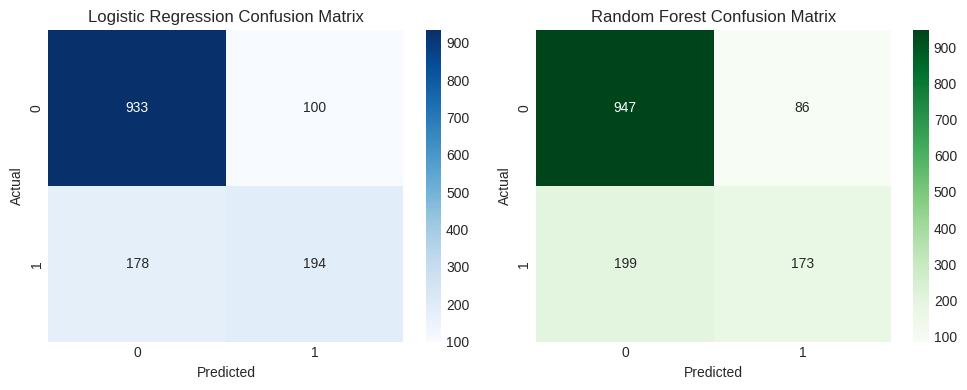

In [11]:
y_pred_lr = lr_model.predict(X_test_scaled)
y_pred_rf = rf_model.predict(X_test)

def get_metrics(name, y_true, y_pred):
    return {
        "Model": name,
        "Accuracy": round(accuracy_score(y_true, y_pred), 4),
        "Precision": round(precision_score(y_true, y_pred), 4),
        "Recall": round(recall_score(y_true, y_pred), 4),
        "F1-Score": round(f1_score(y_true, y_pred), 4)
    }

metrics_df = pd.DataFrame([
    get_metrics("Logistic Regression", y_test, y_pred_lr),
    get_metrics("Random Forest", y_test, y_pred_rf)
])

print("--- Performance Comparison ---")
display(metrics_df)

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
sns.heatmap(confusion_matrix(y_test, y_pred_lr), annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title("Logistic Regression Confusion Matrix")
axes[0].set_xlabel("Predicted")
axes[0].set_ylabel("Actual")

sns.heatmap(confusion_matrix(y_test, y_pred_rf), annot=True, fmt='d', cmap='Greens', ax=axes[1])
axes[1].set_title("Random Forest Confusion Matrix")
axes[1].set_xlabel("Predicted")
axes[1].set_ylabel("Actual")

plt.tight_layout()
plt.show()

In [12]:
def predict_customer_churn(customer_data, model, scaler_obj, feature_cols, is_lr=True):
    input_df = pd.DataFrame([customer_data])

    for col in feature_cols:
        if col not in input_df.columns:
            input_df[col] = 0
    input_df = input_df[feature_cols]

    if is_lr:
        input_df[num_cols] = scaler_obj.transform(input_df[num_cols])

    pred = model.predict(input_df)[0]
    prob = model.predict_proba(input_df)[0][1]

    result = "CHURN (Will Leave)" if pred == 1 else "NO CHURN (Will Stay)"
    return result, prob

sample_customer_1 = {
    'gender': 1, 'SeniorCitizen': 0, 'Partner': 0, 'Dependents': 0,
    'tenure': 2, 'PhoneService': 1, 'MultipleLines': 0, 'OnlineSecurity': 0,
    'OnlineBackup': 0, 'DeviceProtection': 0, 'TechSupport': 0, 'StreamingTV': 1,
    'StreamingMovies': 1, 'PaperlessBilling': 1, 'MonthlyCharges': 85.50,
    'TotalCharges': 171.0, 'InternetService_Fiber optic': 1, 'InternetService_No': 0,
    'Contract_One year': 0, 'Contract_Two year': 0,
    'PaymentMethod_Credit card (automatic)': 0,
    'PaymentMethod_Electronic check': 1,
    'PaymentMethod_Mailed check': 0
}

sample_customer_2 = {
    'gender': 0, 'SeniorCitizen': 0, 'Partner': 1, 'Dependents': 1,
    'tenure': 60, 'PhoneService': 1, 'MultipleLines': 1, 'OnlineSecurity': 1,
    'OnlineBackup': 1, 'DeviceProtection': 1, 'TechSupport': 1, 'StreamingTV': 1,
    'StreamingMovies': 1, 'PaperlessBilling': 0, 'MonthlyCharges': 65.0,
    'TotalCharges': 3900.0, 'InternetService_Fiber optic': 0, 'InternetService_No': 0,
    'Contract_One year': 0, 'Contract_Two year': 1,
    'PaymentMethod_Credit card (automatic)': 1,
    'PaymentMethod_Electronic check': 0,
    'PaymentMethod_Mailed check': 0
}

res1, prob1 = predict_customer_churn(sample_customer_1, lr_model, scaler, X.columns.tolist())
res2, prob2 = predict_customer_churn(sample_customer_2, lr_model, scaler, X.columns.tolist())

print(f"Sample 1 Prediction: {res1} (Probability: {prob1:.2%})")
print(f"Sample 2 Prediction: {res2} (Probability: {prob2:.2%})")

Sample 1 Prediction: CHURN (Will Leave) (Probability: 76.79%)
Sample 2 Prediction: NO CHURN (Will Stay) (Probability: 0.97%)
